# Lesson 6 - Feature Selection for Multi-Omics Data

Companion notebook to `lessons/6_ML_Feature_selection.pptx`.
Fourteen methods on the ASD integrated matrix (100 genes + 50 SNP dosages + Age/Sex):
six filters, three wrappers, four embedded methods and one meta-method, then the
leakage trap and a consensus panel.

In [1]:
# Imports and global settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, f1_score,
                             accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, average_precision_score)
from xgboost import XGBClassifier

RNG = 42
np.random.seed(RNG)
plt.rcParams.update({'font.family': 'Arial', 'figure.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False})
NPG = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488', '#F39B7F', '#8491B4']
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
print('Environment ready.')

Environment ready.


In [2]:
# Load the ASD multi-omics dataset (course data policy: covariates + expression +
# genotype DOSAGE - the continuous 0..2 expected allele counts)
DATA_DIR = "../data/ASD_dataset/"

covariates = pd.read_csv(f"{DATA_DIR}ASD_covariates.csv").set_index('sample')
expression = pd.read_csv(f"{DATA_DIR}ASD_expression.csv").set_index('sample')       # 100 genes
dosage     = pd.read_csv(f"{DATA_DIR}ASD_genotype_dosage.csv").set_index('sample')  # 50 SNP dosages

# Integration presumes IDENTICAL samples across blocks - verify explicitly
assert covariates.index.equals(expression.index) and expression.index.equals(dosage.index), \
    "Sample indices do not match across omics blocks!"

y = covariates['ASD'].values
print(f"Expression: {expression.shape} | Dosage: {dosage.shape} | Covariates: {covariates.shape}")
print(f"Class balance: ASD={y.sum()}, Control={(1-y).sum()}  ({y.mean():.0%} cases)")

Expression: (300, 100) | Dosage: (300, 50) | Covariates: (300, 8)
Class balance: ASD=200, Control=100  (67% cases)


In [3]:
# Integrated feature matrix with per-block prefixes (early fusion) and a
# STRATIFIED 70/30 split; the test set is frozen until final evaluation
X_integrated = pd.concat([
    expression.add_prefix('expr_'),
    dosage.add_prefix('geno_'),
    covariates[['Age', 'Sex']],
], axis=1)
print(f"Integrated matrix: {X_integrated.shape[0]} samples x {X_integrated.shape[1]} features")

X_train, X_test, y_train, y_test = train_test_split(
    X_integrated, y, test_size=0.3, random_state=RNG, stratify=y)

# CRITICAL: scaler is FIT on training data only, then applied to test (no leakage)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=X_train.columns)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  index=X_test.index,  columns=X_test.columns)

print(f"Train: {len(X_train)} ({y_train.mean():.0%} ASD) | Test: {len(X_test)} ({y_test.mean():.0%} ASD)")

Integrated matrix: 300 samples x 152 features
Train: 210 (67% ASD) | Test: 90 (67% ASD)


## Method 1 - Variance threshold (filter)

Applied on the *raw* (pre-standardization) training data: after z-scoring every
feature has variance 1 and the filter is blind.

Variance filter: 152 -> 150 features (2 near-constant removed)


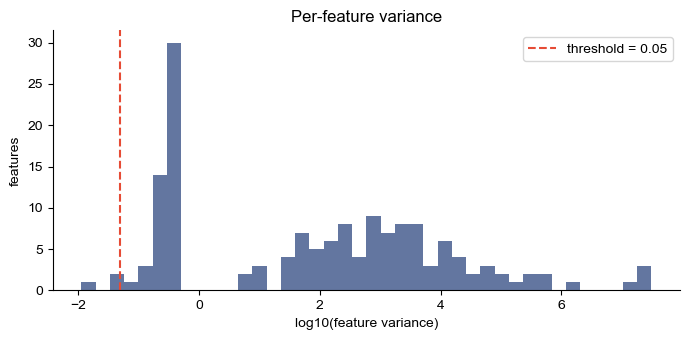

In [4]:
from sklearn.feature_selection import VarianceThreshold

vt = VarianceThreshold(threshold=0.05)
vt.fit(X_train)
kept_vt = X_train.columns[vt.get_support()]
print(f"Variance filter: {X_train.shape[1]} -> {len(kept_vt)} features "
      f"({X_train.shape[1] - len(kept_vt)} near-constant removed)")

variances = X_train.var()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(variances + 1e-9), bins=40, color=NPG[3], alpha=0.8)
ax.axvline(np.log10(0.05), color=NPG[0], ls='--', label='threshold = 0.05')
ax.set(xlabel='log10(feature variance)', ylabel='features', title='Per-feature variance')
ax.legend(); plt.tight_layout(); plt.show()

## Method 2 - Univariate tests: SelectKBest with the ANOVA F-test (filter)

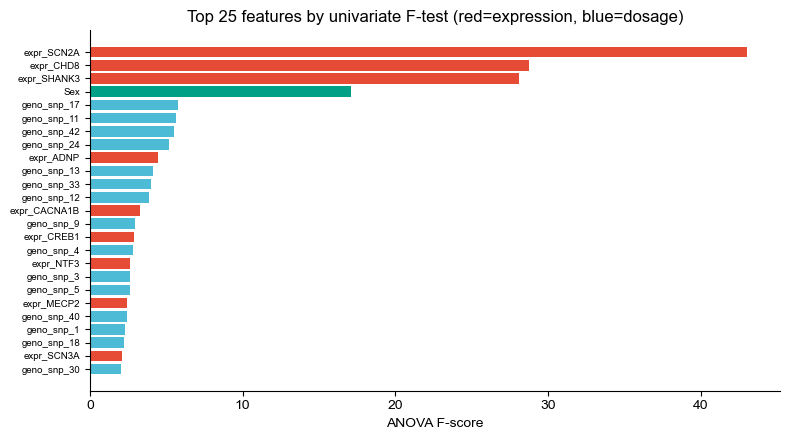

In [5]:
skb = SelectKBest(f_classif, k=30).fit(X_train_s, y_train)
f_scores = pd.Series(skb.scores_, index=X_train.columns).sort_values(ascending=False)
kept_f = set(f_scores.head(30).index)

fig, ax = plt.subplots(figsize=(8, 4.5))
top = f_scores.head(25)
colors = [NPG[0] if c.startswith('expr') else NPG[1] if c.startswith('geno') else NPG[2] for c in top.index]
ax.barh(range(len(top)), top.values, color=colors)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=7)
ax.invert_yaxis(); ax.set_xlabel('ANOVA F-score')
ax.set_title('Top 25 features by univariate F-test (red=expression, blue=dosage)')
plt.tight_layout(); plt.show()

## Method 3 - FDR-controlled selection (filter)

Top-K asks "how many features?"; FDR control asks "how many are REAL?". The
Benjamini-Hochberg procedure - the same machinery as differential expression -
keeps every feature whose sorted p-value falls under the rising line alpha*i/m,
guaranteeing that the EXPECTED fraction of false discoveries among the kept
features is at most alpha.

SelectFdr(alpha=0.05): kept 4 features
  -> among them we EXPECT at most ~0.2 false discoveries
  (contrast with top-K: k=30 was an arbitrary choice with no such guarantee)


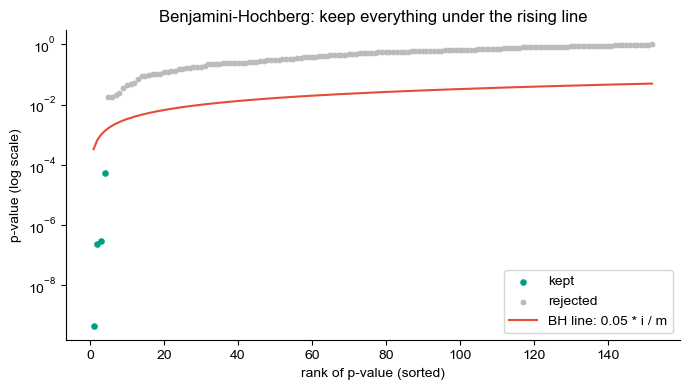

In [6]:
from sklearn.feature_selection import SelectFdr

# BH-controlled selection at FDR alpha = 0.05
fdr_sel = SelectFdr(f_classif, alpha=0.05).fit(X_train_s, y_train)
kept_fdr = set(X_train.columns[fdr_sel.get_support()])
print(f"SelectFdr(alpha=0.05): kept {len(kept_fdr)} features")
print(f"  -> among them we EXPECT at most ~{0.05 * len(kept_fdr):.1f} false discoveries")
print(f"  (contrast with top-K: k=30 was an arbitrary choice with no such guarantee)")

# Visualize the BH procedure itself: sorted p-values vs the rising threshold line
pvals = pd.Series(fdr_sel.pvalues_, index=X_train.columns).sort_values()
m = len(pvals)
ranks_i = np.arange(1, m + 1)
bh_line = 0.05 * ranks_i / m
kept_mask = pvals.values <= bh_line  # simplification for display; sklearn uses the exact BH cutoff

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(ranks_i[kept_mask], pvals.values[kept_mask], s=14, color=NPG[2], label='kept')
ax.scatter(ranks_i[~kept_mask], pvals.values[~kept_mask], s=10, color='#BBBBBB', label='rejected')
ax.plot(ranks_i, bh_line, color=NPG[0], lw=1.5, label='BH line: 0.05 * i / m')
ax.set_yscale('log')
ax.set(xlabel='rank of p-value (sorted)', ylabel='p-value (log scale)',
       title='Benjamini-Hochberg: keep everything under the rising line')
ax.legend(); plt.tight_layout(); plt.show()

## Method 4 - Mutual information (filter)

MI captures *any* dependence, including non-linear ones the F-test misses.

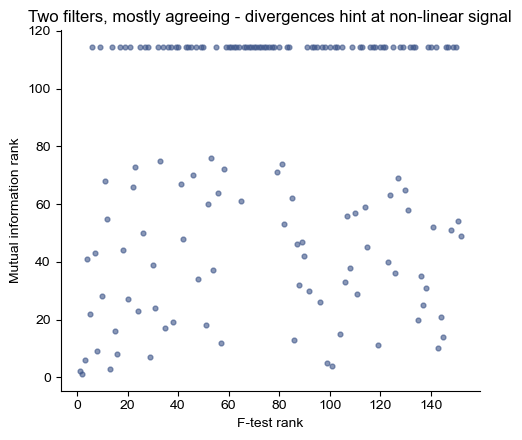

Overlap of top-30 sets: 12/30


In [7]:
from sklearn.feature_selection import mutual_info_classif

mi = pd.Series(mutual_info_classif(X_train_s, y_train, random_state=RNG),
               index=X_train.columns).sort_values(ascending=False)
kept_mi = set(mi.head(30).index)

comp = pd.DataFrame({'F-test rank': f_scores.rank(ascending=False),
                     'MI rank': mi.rank(ascending=False)})
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(comp['F-test rank'], comp['MI rank'], s=12, alpha=0.6, color=NPG[3])
ax.set(xlabel='F-test rank', ylabel='Mutual information rank',
       title='Two filters, mostly agreeing - divergences hint at non-linear signal')
plt.tight_layout(); plt.show()
print(f"Overlap of top-30 sets: {len(kept_f & kept_mi)}/30")

## Method 5 - Correlation / redundancy filtering

Omics features travel in packs (co-expression modules, LD blocks). Drop one of every
pair with |r| > 0.9 among the F-test survivors.

Redundancy pruning: 30 -> 30 features (dropped [])


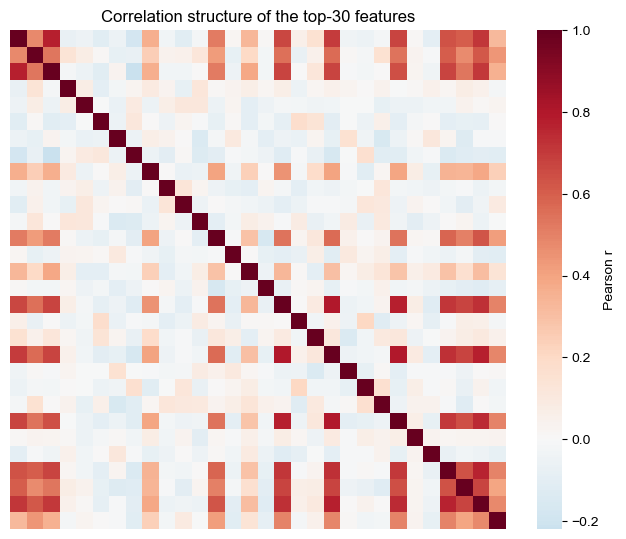

In [8]:
top_cols = list(f_scores.head(30).index)
corr = X_train_s[top_cols].corr().abs()

drop = set()
for i, a in enumerate(top_cols):
    if a in drop: continue
    for b in top_cols[i+1:]:
        if b not in drop and corr.loc[a, b] > 0.9:
            drop.add(b)
kept_corr = [c for c in top_cols if c not in drop]
print(f"Redundancy pruning: 30 -> {len(kept_corr)} features (dropped {sorted(drop)})")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(X_train_s[top_cols].corr(), cmap='RdBu_r', center=0, ax=ax,
            xticklabels=False, yticklabels=False, cbar_kws={'label': 'Pearson r'})
ax.set_title('Correlation structure of the top-30 features')
plt.tight_layout(); plt.show()

## Method 6 - mRMR: maximum relevance, minimum redundancy (filter)

Plain top-K happily keeps 50 copies of the same co-expression module. mRMR builds the
panel greedily, scoring each candidate by relevance to the label MINUS its average
correlation with the features already chosen - so the panel hops between independent
signals instead of restating one. A biomarker-discovery workhorse since the
microarray era; ~20 transparent lines of code.

In [9]:
def mrmr_select(X, y, k=15):
    """Greedy mRMR: relevance (scaled F-score) minus redundancy (mean |r| to picked)."""
    F = pd.Series(f_classif(X, y)[0], index=X.columns)
    F = F / F.max()                                   # relevance on a 0-1 scale
    corr = X.corr().abs()
    selected = [F.idxmax()]                           # start with the most relevant feature
    while len(selected) < k:
        rest = [c for c in X.columns if c not in selected]
        redundancy = corr.loc[rest, selected].mean(axis=1)   # mean |r| to current panel
        score = F[rest] - redundancy
        selected.append(score.idxmax())
    return selected

mrmr_panel = mrmr_select(X_train_s, y_train, k=15)
kept_mrmr = set(mrmr_panel)
topk_panel = list(f_scores.head(15).index)            # plain top-15 for contrast

print("mRMR pick order:", mrmr_panel)
print(f"\nOverlap with plain top-15 by F-score: {len(kept_mrmr & set(topk_panel))}/15")
print("Features mRMR picked that top-K missed (non-redundant signal):")
print(sorted(kept_mrmr - set(topk_panel)))
print("\nInterpretation: top-K stacks correlated winners; mRMR trades a few of them")
print("for features that carry DIFFERENT information - a panel that covers the")
print("signal space instead of repeating its loudest corner.")

mRMR pick order: ['expr_SCN2A', 'Sex', 'expr_CHD8', 'expr_SHANK3', 'geno_snp_42', 'geno_snp_17', 'geno_snp_11', 'geno_snp_13', 'geno_snp_4', 'geno_snp_1', 'geno_snp_12', 'geno_snp_33', 'geno_snp_9', 'geno_snp_24', 'geno_snp_40']

Overlap with plain top-15 by F-score: 12/15
Features mRMR picked that top-K missed (non-redundant signal):
['geno_snp_1', 'geno_snp_4', 'geno_snp_40']

Interpretation: top-K stacks correlated winners; mRMR trades a few of them
for features that carry DIFFERENT information - a panel that covers the
signal space instead of repeating its loudest corner.


## Method 7 - Recursive Feature Elimination (wrapper)

RFECV eliminates the weakest features step by step; CV chooses the panel size.

RFECV optimum: 3 features -> [np.str_('expr_CHD8'), np.str_('expr_SCN2A'), np.str_('expr_SHANK3')]


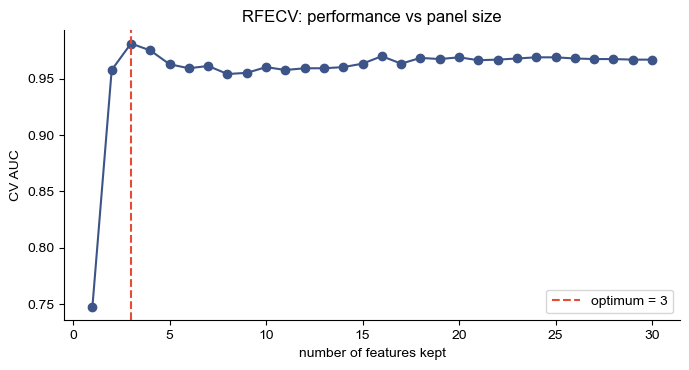

In [10]:
from sklearn.feature_selection import RFECV

rfecv = RFECV(LogisticRegression(max_iter=2000, random_state=RNG),
              step=1, cv=cv5, scoring='roc_auc', n_jobs=-1)
rfecv.fit(X_train_s[kept_corr], y_train)
kept_rfe = set(np.array(kept_corr)[rfecv.support_])
print(f"RFECV optimum: {rfecv.n_features_} features -> {sorted(kept_rfe)}")

mean_scores = rfecv.cv_results_['mean_test_score']
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(1, len(mean_scores) + 1), mean_scores, 'o-', color=NPG[3])
ax.axvline(rfecv.n_features_, color=NPG[0], ls='--', label=f'optimum = {rfecv.n_features_}')
ax.set(xlabel='number of features kept', ylabel='CV AUC', title='RFECV: performance vs panel size')
ax.legend(); plt.tight_layout(); plt.show()

## Method 8 - Sequential forward selection (wrapper)

The most literal wrapper: start from an empty panel and, at each round, add the one
feature whose addition most improves CROSS-VALIDATED AUC - the only criterion that
finally matters. We implement the loop manually so the trajectory is visible
(sklearn's one-liner is `SequentialFeatureSelector(model, direction='forward',
cv=...)`). Greedy caveat: a pair that only works together can be missed.

step  1: + expr_SCN2A         -> CV AUC 0.753
step  2: + expr_CHD8          -> CV AUC 0.967
step  3: + expr_SHANK3        -> CV AUC 0.981
step  4: + geno_snp_13        -> CV AUC 0.984
step  5: + geno_snp_17        -> CV AUC 0.986
step  6: + geno_snp_1         -> CV AUC 0.989
step  7: + expr_DLG4          -> CV AUC 0.990
step  8: + geno_snp_12        -> CV AUC 0.991
step  9: + geno_snp_24        -> CV AUC 0.992
step 10: + geno_snp_33        -> CV AUC 0.992


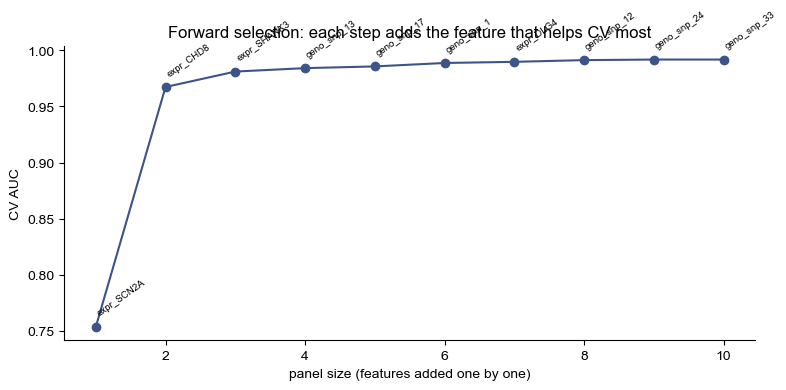


The plateau is the stopping signal: additions beyond it buy nothing.


In [11]:
# Manual forward selection over the redundancy-pruned candidates (kept_corr)
pool = list(kept_corr)
selected_sfs, path_auc, path_names = [], [], []
for step in range(10):                                # build a panel of 10
    best_auc, best_feat = -1, None
    for cand in pool:
        cols = selected_sfs + [cand]
        auc = cross_val_score(LogisticRegression(max_iter=2000, random_state=RNG),
                              X_train_s[cols], y_train, cv=cv5, scoring='roc_auc').mean()
        if auc > best_auc:
            best_auc, best_feat = auc, cand
    selected_sfs.append(best_feat); pool.remove(best_feat)
    path_auc.append(best_auc); path_names.append(best_feat)
    print(f"step {step+1:2d}: + {best_feat:18s} -> CV AUC {best_auc:.3f}")

kept_sfs = set(selected_sfs)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 11), path_auc, 'o-', color=NPG[3])
for i, name in enumerate(path_names):
    ax.annotate(name, (i + 1, path_auc[i]), rotation=35, fontsize=7,
                xytext=(0, 8), textcoords='offset points', ha='left')
ax.set(xlabel='panel size (features added one by one)', ylabel='CV AUC',
       title='Forward selection: each step adds the feature that helps CV most')
plt.tight_layout(); plt.show()
print("\nThe plateau is the stopping signal: additions beyond it buy nothing.")

## Method 9 - L1 / ElasticNet (embedded)

The L1 penalty zeroes out coefficients: whatever survives *is* the selected panel.

In [12]:
l1 = LogisticRegression(penalty='l1', C=0.05, solver='liblinear', max_iter=3000,
                        random_state=RNG).fit(X_train_s, y_train)
coef = pd.Series(l1.coef_[0], index=X_train.columns)
kept_l1 = set(coef[coef != 0].index)
print(f"L1 (C=0.05) kept {len(kept_l1)}/{len(coef)} features:")
print(coef[coef != 0].sort_values(key=abs, ascending=False).round(3).to_string())

en = LogisticRegression(penalty='elasticnet', l1_ratio=0.5, C=0.1, solver='saga',
                        max_iter=5000, random_state=RNG).fit(X_train_s, y_train)
kept_en = set(X_train.columns[en.coef_[0] != 0])
print(f"\nElasticNet kept {len(kept_en)} features (shares weight across correlated genes)")

L1 (C=0.05) kept 3/152 features:
expr_CHD8      0.743
expr_SCN2A    -0.669
expr_SHANK3   -0.170

ElasticNet kept 25 features (shares weight across correlated genes)


## Method 10 - Group lasso: selecting whole omics blocks (embedded)

Multi-omics questions are often about GROUPS, not single features: does the genotype
block add anything once expression is in the model? The group lasso penalizes each
group's JOINT norm, so a block's coefficients hit zero together. No mainstream
sklearn implementation exists, so we fit it with ~20 lines of proximal gradient
descent on the three natural ASD blocks (expression / dosage / covariates).

In [13]:
# Group lasso for linear regression: min ||y - Xw||^2/(2n) + lam * sum_g sqrt(p_g)*||w_g||_2
Xn = X_train_s.values
yn = (y_train - y_train.mean()).astype(float)
groups = {'expression': [i for i, c in enumerate(X_train.columns) if c.startswith('expr_')],
          'dosage':     [i for i, c in enumerate(X_train.columns) if c.startswith('geno_')],
          'covariates': [i for i, c in enumerate(X_train.columns) if c in ('Age', 'Sex')]}

def group_lasso(X, yc, groups, lam, n_iter=800):
    n, p = X.shape
    w = np.zeros(p)
    L = np.linalg.norm(X, 2) ** 2 / n                 # Lipschitz constant of the gradient
    step = 1.0 / L
    for _ in range(n_iter):
        grad = X.T @ (X @ w - yc) / n                 # gradient step on the loss
        w = w - step * grad
        for g, idx in groups.items():                 # proximal step: blockwise soft-threshold
            norm_g = np.linalg.norm(w[idx])
            shrink = step * lam * np.sqrt(len(idx))
            w[idx] = 0.0 if norm_g <= shrink else w[idx] * (1 - shrink / norm_g)
    return w

for lam in [0.01, 0.02, 0.04, 0.15]:
    w = group_lasso(Xn, yn, groups, lam)
    norms = {g: np.linalg.norm(w[idx]) for g, idx in groups.items()}
    status = ', '.join(f"{g}: ||w||={v:.3f}{' (ZEROED)' if v == 0 else ''}" for g, v in norms.items())
    print(f"lam={lam}: {status}")

print("\nTwo lessons in this table. (1) Blocks die as WHOLES - the group lasso")
print("working as designed. (2) Read the ORDER with care: the standard sqrt(group")
print("size) weighting makes LARGE groups expensive to keep, so the 100-gene and")
print("50-SNP blocks are killed before the 2-feature covariate block - the")
print("survivor reflects penalty pricing, not Age/Sex being the best predictors!")
print("Within the paying blocks, dosage shrinks faster than expression (0.065 vs")
print("0.138 at lam=0.02): the same SNP-signal redundancy that Lesson 8's fusion")
print("experiment exposes. Penalties encode assumptions - reading them is part of")
print("reading the model.")

lam=0.01: expression: ||w||=0.269, dosage: ||w||=0.111, covariates: ||w||=0.078
lam=0.02: expression: ||w||=0.138, dosage: ||w||=0.065, covariates: ||w||=0.082
lam=0.04: expression: ||w||=0.000 (ZEROED), dosage: ||w||=0.000 (ZEROED), covariates: ||w||=0.075
lam=0.15: expression: ||w||=0.000 (ZEROED), dosage: ||w||=0.000 (ZEROED), covariates: ||w||=0.000 (ZEROED)

Two lessons in this table. (1) Blocks die as WHOLES - the group lasso
working as designed. (2) Read the ORDER with care: the standard sqrt(group
size) weighting makes LARGE groups expensive to keep, so the 100-gene and
50-SNP blocks are killed before the 2-feature covariate block - the
survivor reflects penalty pricing, not Age/Sex being the best predictors!
Within the paying blocks, dosage shrinks faster than expression (0.065 vs
0.138 at lam=0.02): the same SNP-signal redundancy that Lesson 8's fusion
experiment exposes. Penalties encode assumptions - reading them is part of
reading the model.


## Method 11 - Tree-based SelectFromModel (embedded)

SelectFromModel(threshold='mean'): kept 37 features


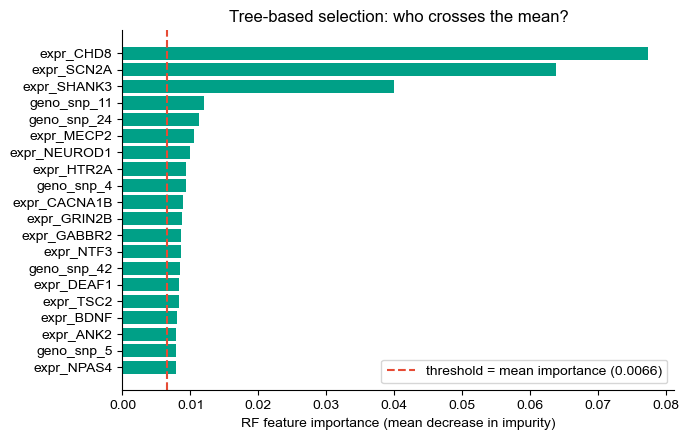

Tree-selected features (importance >= mean): ['Sex', 'expr_ANK2', 'expr_ARID1B', 'expr_BDNF', 'expr_CACNA1B', 'expr_CHD8', 'expr_CREB5', 'expr_DEAF1', 'expr_DRD1', 'expr_EHMT1', 'expr_GABBR2', 'expr_GRIN2B', 'expr_GRM1', 'expr_HTR2A', 'expr_KMT2E', 'expr_MECP2', 'expr_NCAM2', 'expr_NEUROD1', 'expr_NPAS4', 'expr_NTF3', 'expr_NTRK1', 'expr_NTRK3', 'expr_PCLO', 'expr_SCN2A', 'expr_SCN3A', 'expr_SCN8A', 'expr_SHANK3', 'expr_TBR1', 'expr_TSC2', 'geno_snp_11', 'geno_snp_12', 'geno_snp_24', 'geno_snp_37', 'geno_snp_4', 'geno_snp_42', 'geno_snp_5', 'geno_snp_6']


In [20]:
from sklearn.feature_selection import SelectFromModel

rf = RandomForestClassifier(n_estimators=300, random_state=RNG, n_jobs=-1).fit(X_train_s, y_train)
sfm = SelectFromModel(rf, threshold='mean', prefit=True)
kept_tree = set(X_train.columns[sfm.get_support()])
print(f"SelectFromModel(threshold='mean'): kept {len(kept_tree)} features")

imp = pd.Series(rf.feature_importances_, index=X_train.columns)
thr = imp.mean()

top = imp.sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index[::-1], top.values[::-1],
        color=[NPG[2] if v >= thr else '#BBBBBB' for v in top.values[::-1]])
ax.axvline(thr, color=NPG[0], ls='--', label=f'threshold = mean importance ({thr:.4f})')
ax.set_xlabel('RF feature importance (mean decrease in impurity)')
ax.set_title('Tree-based selection: who crosses the mean?')
ax.legend(); plt.tight_layout(); plt.show()

print(f"Tree-selected features (importance >= mean): {sorted(kept_tree)}")

## Method 12 - Boruta-style shadow features (wrapper)

The `boruta` package is unmaintained, so we implement its core idea directly:
shuffled copies of all features ("shadows" = noise with realistic distributions);
confirm only real features that repeatedly beat the **best shadow**.

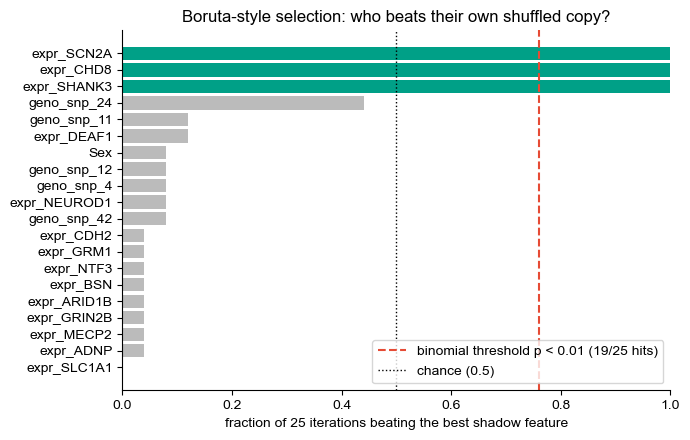

Boruta-style confirmed 3 features after 25 iterations:
['expr_CHD8', 'expr_SCN2A', 'expr_SHANK3']

Best shadow importance per iteration: mean 0.0094, max 0.0173


In [21]:
from scipy.stats import binomtest

n_iter, hits = 25, pd.Series(0, index=X_train.columns)
shadow_max = []
for it in range(n_iter):
    shadows = X_train_s.sample(frac=1.0, random_state=it).reset_index(drop=True)
    shadows.columns = ['shadow_' + c for c in shadows.columns]
    Xb = pd.concat([X_train_s.reset_index(drop=True), shadows], axis=1)
    rf_b = RandomForestClassifier(n_estimators=150, random_state=it, n_jobs=-1).fit(Xb, y_train)
    imp_b = pd.Series(rf_b.feature_importances_, index=Xb.columns)
    best_shadow = imp_b[imp_b.index.str.startswith('shadow_')].max()
    shadow_max.append(best_shadow)
    hits += (imp_b[X_train.columns] > best_shadow).astype(int)

pvals = pd.Series({f: binomtest(int(hits[f]), n_iter, 0.5, alternative='greater').pvalue
                   for f in X_train.columns})
confirmed = list(pvals[pvals < 0.01].index)
kept_boruta = set(confirmed)

# smallest number of hits that is significant at p < 0.01 -> plotted as the threshold
min_hits = next(k for k in range(n_iter + 1)
                if binomtest(k, n_iter, 0.5, alternative='greater').pvalue < 0.01)
thr = min_hits / n_iter

hit_rate = hits / n_iter
top = hit_rate.sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index[::-1], top.values[::-1],
        color=[NPG[2] if f in kept_boruta else '#BBBBBB' for f in top.index[::-1]])
ax.axvline(thr, color=NPG[0], ls='--',
           label=f'binomial threshold p < 0.01 ({min_hits}/{n_iter} hits)')
ax.axvline(0.5, color='k', ls=':', lw=1, label='chance (0.5)')
ax.set_xlim(0, 1)
ax.set_xlabel(f'fraction of {n_iter} iterations beating the best shadow feature')
ax.set_title('Boruta-style selection: who beats their own shuffled copy?')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

print(f"Boruta-style confirmed {len(confirmed)} features after {n_iter} iterations:")
print(sorted(confirmed))
print(f"\nBest shadow importance per iteration: mean {np.mean(shadow_max):.4f}, "
      f"max {np.max(shadow_max):.4f}")

## Method 13 - Stability selection: vote across resamples

A panel selected once is a lottery ticket; a panel selected in 80% of resamples is
evidence (Meinshausen & Buhlmann 2010, with false-discovery guarantees). Recipe:
subsample half the cohort, run the L1 selector, repeat 100x, and report each
feature's SELECTION FREQUENCY - the selection-side mirror of Lesson 8's consensus
clustering.

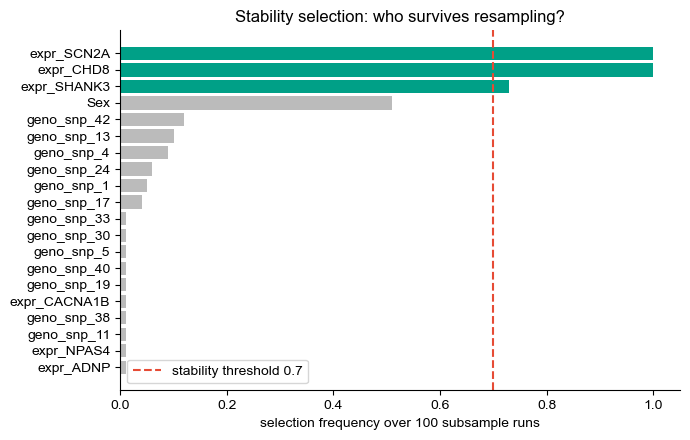

Stable features (freq >= 0.7): ['expr_CHD8', 'expr_SCN2A', 'expr_SHANK3']

Compare with ANY single L1 run above: the one-shot panel contains lottery
tickets that vanish on a different subsample; the frequency plot separates
them from load-bearing biology at a glance.


In [16]:
n_boot, half = 100, len(X_train_s) // 2
freq = pd.Series(0.0, index=X_train.columns)
for b in range(n_boot):
    idx = np.random.default_rng(b).choice(len(X_train_s), half, replace=False)
    l1b = LogisticRegression(penalty='l1', C=0.1, solver='liblinear',
                             max_iter=3000, random_state=RNG)
    l1b.fit(X_train_s.iloc[idx], y_train[idx])
    freq += (l1b.coef_[0] != 0).astype(float)
freq /= n_boot
kept_stab = set(freq[freq >= 0.7].index)

top = freq.sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index[::-1], top.values[::-1],
        color=[NPG[2] if v >= 0.7 else '#BBBBBB' for v in top.values[::-1]])
ax.axvline(0.7, color=NPG[0], ls='--', label='stability threshold 0.7')
ax.set_xlabel('selection frequency over 100 subsample runs')
ax.set_title('Stability selection: who survives resampling?')
ax.legend(); plt.tight_layout(); plt.show()

print(f"Stable features (freq >= 0.7): {sorted(kept_stab)}")
print("\nCompare with ANY single L1 run above: the one-shot panel contains lottery")
print("tickets that vanish on a different subsample; the frequency plot separates")
print("them from load-bearing biology at a glance.")

## Method 14 - DIABLO: multi-omics selection (embedded)

DIABLO (mixOmics, R) selects **matched multi-omics signatures**: sparse latent
components per block that correlate across omics AND separate the classes. It runs in
R through the course Docker image (full pipeline: `notebooks/diablo.ipynb`); here we
load and interpret the precomputed results shipped with the course data.

DIABLO classification performance (5-fold CV x 10 repeats, balanced error rate):
 Component  Overall_Error  Control_Error  ASD_Error   BER
         1          0.301          0.276      0.314 0.295
         2          0.241          0.236      0.244 0.240

Cross-block correlation of the components:
 Component  Expression_Genotypes_Cor
         1                     0.552
         2                     0.136


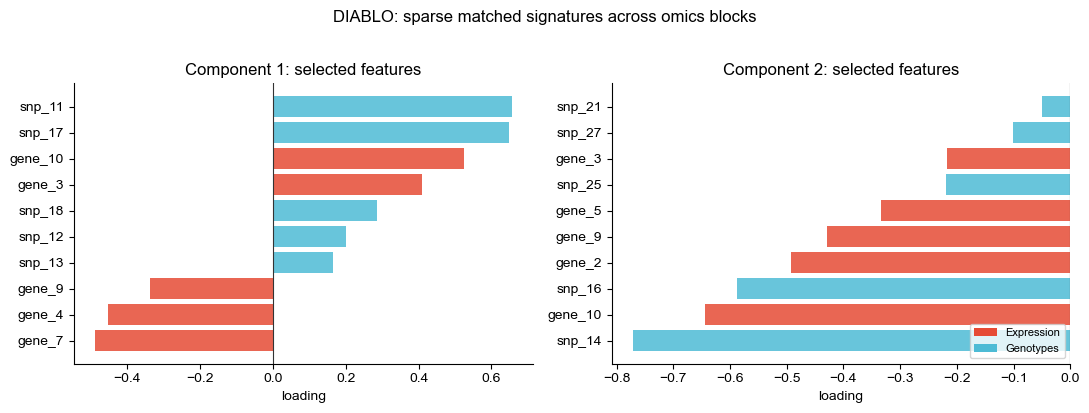


Interpretation: each component pairs a handful of genes with a handful of
SNPs that vary together AND separate ASD from controls - candidate gene-SNP
modules. Component 1 block correlation: 0.55.


In [17]:
diablo_sel  = pd.read_csv(f"{DATA_DIR}DIABLO_final_selected_features.csv")
diablo_perf = pd.read_csv(f"{DATA_DIR}DIABLO_final_performance.csv")
diablo_corr = pd.read_csv(f"{DATA_DIR}DIABLO_final_correlations.csv")

print("DIABLO classification performance (5-fold CV x 10 repeats, balanced error rate):")
print(diablo_perf.round(3).to_string(index=False))
print("\nCross-block correlation of the components:")
print(diablo_corr.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, comp in zip(axes, [1, 2]):
    sub = diablo_sel[diablo_sel['Component'] == comp].sort_values('Loading')
    colors = [NPG[0] if b == 'Expression' else NPG[1] for b in sub['Block']]
    ax.barh(sub['Feature'], sub['Loading'], color=colors, alpha=0.85)
    ax.axvline(0, color='#333333', lw=0.8)
    ax.set_title(f'Component {comp}: selected features')
    ax.set_xlabel('loading')
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(fc=NPG[0], label='Expression'), Patch(fc=NPG[1], label='Genotypes')],
               fontsize=8, loc='lower right')
plt.suptitle('DIABLO: sparse matched signatures across omics blocks', y=1.02)
plt.tight_layout(); plt.show()

print("\nInterpretation: each component pairs a handful of genes with a handful of")
print("SNPs that vary together AND separate ASD from controls - candidate gene-SNP")
print(f"modules. Component 1 block correlation: {diablo_corr.iloc[0, 1]:.2f}.")

## The leakage trap - selection must live INSIDE the CV loop

On **pure random noise** (no signal exists), selecting features on all data before CV
manufactures an excellent AUC; the correct `Pipeline` approach reports the truth (~0.5).

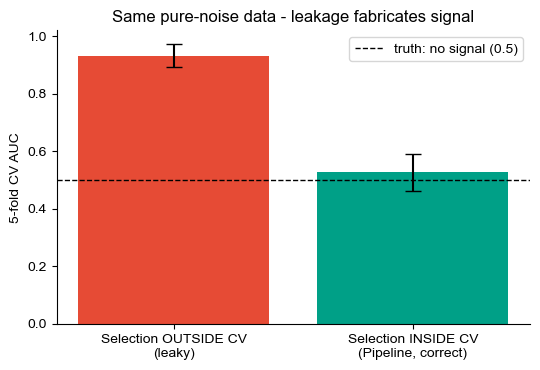

Leaky AUC:   0.932 +/- 0.040   <- fabricated!
Correct AUC: 0.527 +/- 0.065   <- honest


In [18]:
rng = np.random.default_rng(RNG)
X_noise = rng.normal(size=(100, 2000))
y_noise = rng.integers(0, 2, 100)

# WRONG: select on ALL data, then cross-validate on the chosen features
X_leaky = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
auc_leaky = cross_val_score(LogisticRegression(max_iter=2000), X_leaky, y_noise,
                            cv=5, scoring='roc_auc')

# RIGHT: selection re-fit inside every fold via Pipeline
pipe = Pipeline([('select', SelectKBest(f_classif, k=20)),
                 ('clf', LogisticRegression(max_iter=2000))])
auc_ok = cross_val_score(pipe, X_noise, y_noise, cv=5, scoring='roc_auc')

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(['Selection OUTSIDE CV\n(leaky)', 'Selection INSIDE CV\n(Pipeline, correct)'],
       [auc_leaky.mean(), auc_ok.mean()],
       yerr=[auc_leaky.std(), auc_ok.std()], color=[NPG[0], NPG[2]], capsize=6)
ax.axhline(0.5, color='k', ls='--', lw=1, label='truth: no signal (0.5)')
ax.set_ylabel('5-fold CV AUC'); ax.set_title('Same pure-noise data - leakage fabricates signal')
ax.legend(); plt.tight_layout(); plt.show()
print(f"Leaky AUC:   {auc_leaky.mean():.3f} +/- {auc_leaky.std():.3f}   <- fabricated!")
print(f"Correct AUC: {auc_ok.mean():.3f} +/- {auc_ok.std():.3f}   <- honest")

## Consensus across selection methods

Features chosen by many independent methods are the robust candidates; the panel
feeds Lesson 7's importance analysis.

Features selected by >= 5 of 7 methods (high-confidence candidates):
expr_CHD8      7
expr_SHANK3    7
expr_SCN2A     7


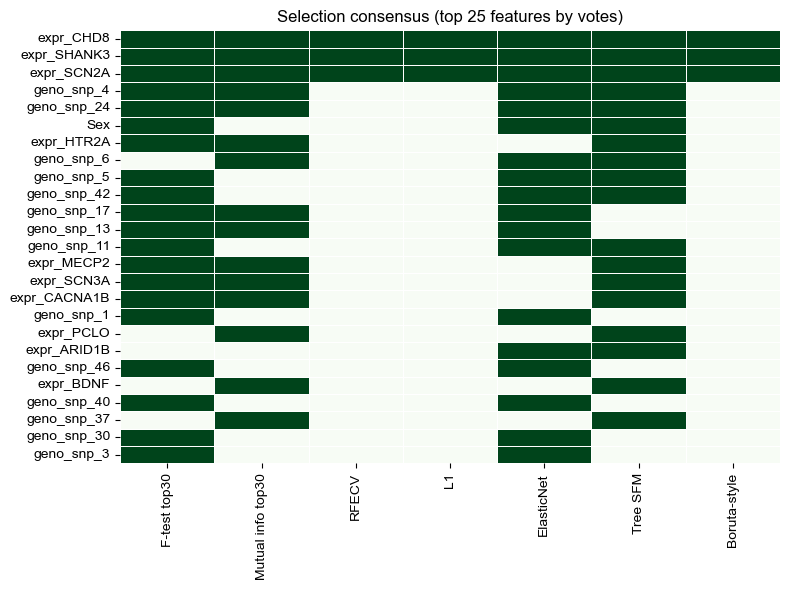


16 candidates carried into Lesson 7: ['expr_SCN2A', 'expr_CHD8', 'expr_SHANK3', 'geno_snp_24', 'geno_snp_4', 'Sex', 'geno_snp_17', 'geno_snp_11', 'geno_snp_42', 'geno_snp_13', 'expr_CACNA1B', 'geno_snp_5', 'expr_MECP2', 'expr_SCN3A', 'expr_HTR2A', 'geno_snp_6']


In [19]:
methods = {'F-test top30': kept_f, 'Mutual info top30': kept_mi,
           'RFECV': kept_rfe, 'L1': kept_l1, 'ElasticNet': kept_en,
           'Tree SFM': kept_tree, 'Boruta-style': kept_boruta}
all_selected = sorted(set().union(*methods.values()))
votes = pd.DataFrame({m: [f in s for f in all_selected] for m, s in methods.items()},
                     index=all_selected)
votes['votes'] = votes.sum(axis=1)
consensus = votes.sort_values('votes', ascending=False)
print("Features selected by >= 5 of 7 methods (high-confidence candidates):")
print(consensus[consensus['votes'] >= 5]['votes'].to_string())

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(consensus.drop(columns='votes').head(25).astype(int), cmap='Greens',
            cbar=False, linewidths=0.5, ax=ax)
ax.set_title('Selection consensus (top 25 features by votes)')
plt.tight_layout(); plt.show()

by_priority = consensus.assign(F=f_scores.reindex(consensus.index)) \
                       .sort_values(['votes', 'F'], ascending=False)
panel_candidates = list(by_priority[by_priority['votes'] >= 3].index)
if len(panel_candidates) < 12:
    extra = [f for f in by_priority.index if f not in panel_candidates]
    panel_candidates += extra[:12 - len(panel_candidates)]
print(f"\n{len(panel_candidates)} candidates carried into Lesson 7: {panel_candidates}")

## Lesson 6 summary

- Filters (variance, F-test, MI, redundancy): fast first cuts
- Wrappers (RFE, Boruta): context-aware, compute-hungry
- Embedded (Lasso/ElasticNet, trees, DIABLO): selection while training
- DIABLO selects matched signatures ACROSS omics blocks
- Selection ALWAYS inside the CV loop: leakage fabricates AUC
- Stability and consensus separate biomarkers from lottery tickets

Next: `7_ML_feature_importances.ipynb` - quantifying each feature's contribution.